# RAID-KL + VanillaKD — DNN Teacher (v1 fixed τ | v2 adaptive τ | v3 VanillaKD)

Train **3 student DNN song song theo epoch** (chung teacher + data).

**Cập nhật:**
- **Student chia 4 chiều rộng**: DNN `[256, 256, 256]` → `[64, 64, 64]`.
- **Class weight** từ `class_weights_p3.json` (key `weights_balanced`, clip max=3, chỉ vào CE).
- **Optimizer: Adam, KHÔNG weight decay** (khớp teacher Keras dùng Adam).
- Teacher Keras → convert PyTorch (sanity-check argmax 100%).

v1 RAID fixed τ=7 | v2 RAID adaptive τ∈[2,7] | v3 VanillaKD T=3 α=0.5. α=0.5, λ=0.3.
Lưu 3 `.pth` state_dict, checkpoint độc lập, size `count_params()×4/1024²`, plots lưới 3×3.


## Cell 1 — Cấu hình & Import

In [1]:
!pip install -q pyarrow pandas scikit-learn torch tensorflow matplotlib seaborn

import os, gc, time, glob, warnings, json, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    classification_report, roc_auc_score,
    accuracy_score, confusion_matrix, f1_score
)

warnings.filterwarnings('ignore')

INPUT_DIR    = '/kaggle/input/datasets/rsnngo/37ft-thang3737'
TEACHER_DIR  = '/kaggle/input/datasets/rsnngo/teacher-model-thang3737'
TEACHER_KERAS_PATH = f'{TEACHER_DIR}/dnn_after_optuna_37ft.keras'
TEACHER_PTH_CACHE  = '/kaggle/working/teacher_dnn_converted.pth'
OUTPUT_DIR   = '/kaggle/working/'
TRAIN_FILE   = os.path.join(INPUT_DIR, 'train_standard_p3.2.parquet')
VAL_FILE     = os.path.join(INPUT_DIR, 'val_standard_p3.2.parquet')
TEST_FILE    = os.path.join(INPUT_DIR, 'test_standard_p3.2.parquet')
CLASS_WEIGHTS_JSON = os.path.join(INPUT_DIR, 'class_weights_p3.2.json')

V1_PATH = os.path.join(OUTPUT_DIR, 'student_dnn_fix_t_classw3_37ft.pth')
V2_PATH = os.path.join(OUTPUT_DIR, 'student_dnn_adapt_t_classw3_37ft.pth')
V3_PATH = os.path.join(OUTPUT_DIR, 'student_dnn_vanilla_kd_classw3_37ft.pth')
V1_CKPT_DIR = os.path.join(OUTPUT_DIR, 'ckpt_v1')
V2_CKPT_DIR = os.path.join(OUTPUT_DIR, 'ckpt_v2')
V3_CKPT_DIR = os.path.join(OUTPUT_DIR, 'ckpt_v3')
for d in [OUTPUT_DIR, V1_CKPT_DIR, V2_CKPT_DIR, V3_CKPT_DIR]:
    os.makedirs(d, exist_ok=True)

NUM_FEATURES = 37
NUM_CLASSES  = 8
LABEL_COL    = 'label'
FILTERS_TEACHER = [256, 256, 256]
FILTERS_STUDENT = [64, 64, 64]
TEACHER_EMBED_DIM = 256
STUDENT_EMBED_DIM = 64
DROPOUT_RATE = 0.1
LABEL_NAMES = {0:'Benign',1:'DDoS',2:'DoS',3:'BruteForce',
               4:'Spoofing',5:'Recon',6:'Web-Based',7:'Mirai'}
CLASS_NAMES = [LABEL_NAMES[i] for i in range(NUM_CLASSES)]
COLORS = ['#4C9BE8','#E84C4C','#F5A623','#9B59B6',
          '#2ECC71','#1ABC9C','#8B4513','#607D8B']

BATCH_SIZE       = 512
N_EPOCHS         = 50
LR               = 0.001685
CHECKPOINT_EVERY = 5
RANDOM_SEED      = 42
CLASS_WEIGHT_MAX = 3.0

ALPHA=0.5; LAMBDA=0.3
TAU_FIXED=7.0; TAU_MIN=2.0; TAU_MAX=7.0
VKD_ALPHA=0.5; VKD_T=3

torch.manual_seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('='*64)
print('  RAID-KL + VanillaKD -- DNN (student chia 4 + class weight)')
print('='*64)
print(f'  Device: {DEVICE} | Batch/LR: {BATCH_SIZE}/{LR} | Optimizer: Adam (KHONG weight decay)')
print(f'  Teacher {FILTERS_TEACHER} -> Student {FILTERS_STUDENT} (chia 4)')
print(f'  α={ALPHA} λ={LAMBDA} | v1 τ={TAU_FIXED} | v2 τ∈[{TAU_MIN},{TAU_MAX}] | VKD T={VKD_T}')
print('='*64)


  RAID-KL + VanillaKD -- DNN (student chia 4 + class weight)
  Device: cuda | Batch/LR: 512/0.001685 | Optimizer: Adam (KHONG weight decay)
  Teacher [256, 256, 256] -> Student [64, 64, 64] (chia 4)
  α=0.5 λ=0.3 | v1 τ=7.0 | v2 τ∈[2.0,7.0] | VKD T=3


## Cell 2 — Load class weights (`weights_balanced`, clip max=3)

In [2]:
def load_class_weights(json_path, num_classes=NUM_CLASSES, clip_max=CLASS_WEIGHT_MAX):
    """Doc class_weights_p3.json, lay 'weights_balanced', clip max."""
    with open(json_path, 'r') as f:
        raw = json.load(f)
    weights = np.ones(num_classes, dtype=np.float32)
    if isinstance(raw, dict) and any(k in raw for k in ('weights_balanced','class_weights','weights')):
        for key in ('weights_balanced','class_weights','weights'):
            if key in raw:
                arr = raw[key]
                assert len(arr) == num_classes, f'{key} len {len(arr)} != {num_classes}'
                weights = np.array(arr, dtype=np.float32)
                print(f'  Lay class weight tu key "{key}"')
                break
    elif isinstance(raw, list):
        assert len(raw) == num_classes
        weights = np.array(raw, dtype=np.float32)
    elif isinstance(raw, dict):
        name_to_idx = {v: k for k, v in LABEL_NAMES.items()}
        for k, val in raw.items():
            idx = int(k) if str(k).isdigit() else name_to_idx[k]
            weights[idx] = float(val)
    weights_clipped = np.minimum(weights, clip_max)
    return torch.tensor(weights_clipped, dtype=torch.float32, device=DEVICE), weights

try:
    class_weights, class_weights_raw = load_class_weights(CLASS_WEIGHTS_JSON)
    print(f'Class weights (balanced -> clip max={CLASS_WEIGHT_MAX:.1f}):')
    for i in range(NUM_CLASSES):
        clip = ' <- CLIP' if class_weights_raw[i] > CLASS_WEIGHT_MAX else ''
        print(f'  [{i}] {LABEL_NAMES[i]:12s}: {class_weights_raw[i]:8.4f} -> {class_weights[i].item():.4f}{clip}')
except FileNotFoundError:
    print(f'CANH BAO: khong thay {CLASS_WEIGHTS_JSON} -> class_weights=None')
    class_weights = None


  Lay class weight tu key "weights_balanced"
Class weights (balanced -> clip max=3.0):
  [0] Benign      :   0.8334 -> 0.8334
  [1] DDoS        :   0.2914 -> 0.2914
  [2] DoS         :   0.9012 -> 0.9012
  [3] BruteForce  :  69.7046 -> 3.0000 <- CLIP
  [4] Spoofing    :   2.0023 -> 2.0023
  [5] Recon       :   1.4567 -> 1.4567
  [6] Web-Based   :  36.8116 -> 3.0000 <- CLIP
  [7] Mirai       :   0.9697 -> 0.9697


## Cell 3 — Dataset

In [3]:
class ParquetDataset(Dataset):
    def __init__(self, path):
        df = pd.read_parquet(path)
        fc = [c for c in df.columns if c != LABEL_COL]
        assert len(fc) == NUM_FEATURES
        self.X = torch.from_numpy(df[fc].to_numpy(dtype=np.float32))
        self.y = torch.from_numpy(df[LABEL_COL].to_numpy(dtype=np.int64))
        print(f'  {path.split("/")[-1]}: {len(self.X):,} mau')
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

print('Dang doc du lieu ...')
train_ds = ParquetDataset(TRAIN_FILE)
val_ds   = ParquetDataset(VAL_FILE)
test_ds  = ParquetDataset(TEST_FILE)
kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, shuffle=True,  **kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **kw)
print(f'Dataset san sang | train {len(train_loader):,} batches')


Dang doc du lieu ...
  train_standard_p3.2.parquet: 4,468,344 mau
  val_standard_p3.2.parquet: 1,117,087 mau
  test_standard_p3.2.parquet: 1,396,358 mau
Dataset san sang | train 8,728 batches


## Cell 4 — Kiến trúc Teacher & 3 Student (DNN chia 4)

Teacher `[256,256,256]` (Keras→PyTorch). Student MiniDNN `[64,64,64]`.
feat_t (adaptive τ) = hidden cuối teacher 256-dim; proj student 64→256.

In [4]:
# Teacher DNN [256,256,256]: Linear->ReLU->BN(eps1e-3)->Dropout, tach body/head
class DNNPlainWithFeat(nn.Module):
    def __init__(self, hidden=FILTERS_TEACHER):
        super().__init__()
        layers=[]; d=NUM_FEATURES
        for u in hidden:
            layers += [nn.Linear(d,u), nn.ReLU(), nn.BatchNorm1d(u,eps=1e-3), nn.Dropout(DROPOUT_RATE)]
            d=u
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d, NUM_CLASSES)
    def forward(self, x): return self.head(self.body(x))
    def forward_feat(self, x):
        feat = self.body(x); return self.head(feat), feat   # feat 256-dim

# Student body [64,64,64]
class MiniDNNBody(nn.Module):
    def __init__(self, hidden=FILTERS_STUDENT):
        super().__init__()
        layers=[]; d=NUM_FEATURES
        for u in hidden:
            layers += [nn.Linear(d,u), nn.ReLU(), nn.BatchNorm1d(u,eps=1e-3), nn.Dropout(DROPOUT_RATE)]
            d=u
        self.net = nn.Sequential(*layers); self.out_dim = d
    def forward(self, x): return self.net(x)

class StudentV1(nn.Module):
    def __init__(self):
        super().__init__(); self.body=MiniDNNBody(); self.head=nn.Linear(STUDENT_EMBED_DIM,NUM_CLASSES)
    def forward(self,x): return self.head(self.body(x))
class StudentV2(nn.Module):
    def __init__(self):
        super().__init__(); self.body=MiniDNNBody(); self.head=nn.Linear(STUDENT_EMBED_DIM,NUM_CLASSES)
        self.proj=nn.Linear(STUDENT_EMBED_DIM,TEACHER_EMBED_DIM,bias=False)  # 64->256
    def forward(self,x):
        f=self.body(x); return self.head(f), self.proj(f)
class StudentV3(nn.Module):
    def __init__(self):
        super().__init__(); self.body=MiniDNNBody(); self.head=nn.Linear(STUDENT_EMBED_DIM,NUM_CLASSES)
    def forward(self,x): return self.head(self.body(x))

def count_params(m): return sum(p.numel() for p in m.parameters())
_t=count_params(DNNPlainWithFeat())
for nm,cls in [('v1',StudentV1),('v2',StudentV2),('v3',StudentV3)]:
    sp=count_params(cls()); print(f'Student {nm}: {sp:,}  compression {1-sp/_t:.1%}')
print(f'Teacher: {_t:,}')


Student v1: 11,656  compression 92.0%
Student v2: 28,040  compression 80.6%
Student v3: 11,656  compression 92.0%
Teacher: 144,904


## Cell 5 — Loss (class weight chỉ vào CE)

In [5]:
def js_divergence(p,q):
    m=0.5*(p+q)
    return 0.5*F.kl_div((m+1e-8).log(),p+1e-8,reduction='batchmean')+0.5*F.kl_div((m+1e-8).log(),q+1e-8,reduction='batchmean')
def ce_weighted(logits,labels): return F.cross_entropy(logits,labels,weight=class_weights)
def raid_kl_loss_v1(ls,lt,y):
    tau=TAU_FIXED; pt=F.softmax(lt/tau,-1); ps=F.softmax(ls/tau,-1)
    kl=F.kl_div((ps+1e-8).log(),pt+1e-8,reduction='batchmean'); js=js_divergence(pt,ps)
    return (1-LAMBDA)*ce_weighted(ls,y)+LAMBDA*(tau**2)*(ALPHA*kl+(1-ALPHA)*js)
def adaptive_temperature(ft,fsp):
    ft=F.normalize(ft,dim=-1); fs=F.normalize(fsp,dim=-1)
    cos=(ft*fs).sum(-1).mean()
    return (TAU_MIN+(TAU_MAX-TAU_MIN)*(1-cos)).clamp(TAU_MIN,TAU_MAX)
def raid_kl_loss_v2(ls,lt,ft,fsp,y):
    tau=adaptive_temperature(ft,fsp); pt=F.softmax(lt/tau,-1); ps=F.softmax(ls/tau,-1)
    kl=F.kl_div((ps+1e-8).log(),pt+1e-8,reduction='batchmean'); js=js_divergence(pt,ps)
    return (1-LAMBDA)*ce_weighted(ls,y)+LAMBDA*(tau**2)*(ALPHA*kl+(1-ALPHA)*js)
def vanilla_kd_loss(ls,lt,y):
    pt=F.softmax(lt/VKD_T,-1); lps=F.log_softmax(ls/VKD_T,-1)
    return VKD_ALPHA*F.kl_div(lps,pt,reduction='batchmean')*(VKD_T**2)+(1-VKD_ALPHA)*ce_weighted(ls,y)
print('Loss san sang (class weight chi vao CE)')


Loss san sang (class weight chi vao CE)


## Cell 6 — Load Teacher (Keras → PyTorch, frozen)

In [6]:
import tensorflow as tf
def load_teacher(keras_path):
    km=tf.keras.models.load_model(keras_path); tm=DNNPlainWithFeat()
    kw=[l for l in km.layers if l.get_weights()]
    tl=[m for m in tm.body if isinstance(m,(nn.Linear,nn.BatchNorm1d))]; tl.append(tm.head)
    assert len(kw)==len(tl), f'{len(kw)} != {len(tl)}'
    for k,t in zip(kw,tl):
        w=k.get_weights()
        if isinstance(t,nn.Linear):
            t.weight.data=torch.from_numpy(w[0].T.copy()).float(); t.bias.data=torch.from_numpy(w[1]).float()
        else:
            t.weight.data=torch.from_numpy(w[0]).float(); t.bias.data=torch.from_numpy(w[1]).float()
            t.running_mean.data=torch.from_numpy(w[2]).float(); t.running_var.data=torch.from_numpy(w[3]).float()
    tm.eval(); return tm,km

print('Load & convert teacher DNN ...')
t_model,_km=load_teacher(TEACHER_KERAS_PATH)
t_model.to(DEVICE).eval()
for p in t_model.parameters(): p.requires_grad=False
t_params=count_params(t_model)

@torch.no_grad()
def teacher_forward(x): return t_model.forward_feat(x)

_xn=train_ds.X[:256].numpy(); _xt=train_ds.X[:256].to(DEVICE)
_kp=np.argmax(_km.predict(_xn,verbose=0),axis=1)
_lt,_ft=teacher_forward(_xt); _tp=_lt.argmax(1).cpu().numpy()
assert np.array_equal(_kp,_tp), 'CONVERT LOI!'
assert _ft.shape[1]==TEACHER_EMBED_DIM
print(f'Sanity argmax khop 100% | Teacher params: {t_params:,} | feat {_ft.shape[1]}')
del _xn,_xt,_kp,_lt,_ft,_tp; gc.collect()
try: tf.keras.backend.clear_session()
except: pass


Load & convert teacher DNN ...


I0000 00:00:1785725739.339050      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13754 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785725739.341251      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1785725741.723071      84 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Sanity argmax khop 100% | Teacher params: 144,904 | feat 256


## Cell 7 — Khởi tạo 3 Student & Optimizer (Adam, KHÔNG weight decay)

In [7]:
def find_latest_ckpt(d):
    fs=sorted(glob.glob(os.path.join(d,'ckpt_student_epoch_*.pth'))); return fs[-1] if fs else None
def init_student(model_cls, ckpt_dir, version):
    student=model_cls().to(DEVICE)
    optimizer=optim.Adam(student.parameters(), lr=LR)   # Adam, KHONG weight decay
    start_epoch=1; train_losses,val_losses=[],[]; best_val_loss=float('inf'); best_state=None
    latest=find_latest_ckpt(ckpt_dir)
    if latest:
        ck=torch.load(latest,map_location='cpu')
        student.load_state_dict(ck['model_state']); student.to(DEVICE)
        start_epoch=ck['epoch']+1; train_losses=ck.get('train_losses',[]); val_losses=ck.get('val_losses',[])
        best_val_loss=ck.get('best_val_loss',float('inf'))
        best_state={k:v.clone() for k,v in student.state_dict().items()}
        print(f'  [{version}] Resume epoch {start_epoch}')
    else:
        print(f'  [{version}] Train tu dau')
    return student,optimizer,start_epoch,train_losses,val_losses,best_val_loss,best_state

(student_v1,opt_v1,start_v1,tl_v1,vl_v1,bvl_v1,bs_v1)=init_student(StudentV1,V1_CKPT_DIR,'v1')
(student_v2,opt_v2,start_v2,tl_v2,vl_v2,bvl_v2,bs_v2)=init_student(StudentV2,V2_CKPT_DIR,'v2')
(student_v3,opt_v3,start_v3,tl_v3,vl_v3,bvl_v3,bs_v3)=init_student(StudentV3,V3_CKPT_DIR,'v3')
print(f'\nParams v1/v2/v3: {count_params(student_v1):,}/{count_params(student_v2):,}/{count_params(student_v3):,}')
print(f'Compression (v1): {1-count_params(student_v1)/t_params:.1%}')


  [v1] Train tu dau
  [v2] Train tu dau
  [v3] Train tu dau

Params v1/v2/v3: 11,656/28,040/11,656
Compression (v1): 92.0%


## Cell 8 — Training Loop (3 student song song theo epoch)

In [8]:
def save_ckpt(d,epoch,bs,tl,vl,bvl):
    torch.save({'epoch':epoch,'model_state':bs,'train_losses':tl,'val_losses':vl,'best_val_loss':bvl},
               os.path.join(d,f'ckpt_student_epoch_{epoch:04d}.pth'))

start_epoch=min(start_v1,start_v2,start_v3)
if start_v1>N_EPOCHS and start_v2>N_EPOCHS and start_v3>N_EPOCHS:
    print('Da train xong. Load best.')
    student_v1.load_state_dict(bs_v1); student_v2.load_state_dict(bs_v2); student_v3.load_state_dict(bs_v3)
    student_v1.to(DEVICE); student_v2.to(DEVICE); student_v3.to(DEVICE)
else:
    t_model.eval()
    print(f'[KD] Train tu epoch {start_epoch}/{N_EPOCHS}')
    print(f'{"Epoch":>6} | {"v1 Tr":>8} {"v1 Vl":>8} | {"v2 Tr":>8} {"v2 Vl":>8} | {"v3 Tr":>8} {"v3 Vl":>8} | {"LR":>9}')
    print('-'*88)
    t0=time.time()
    for epoch in range(start_epoch,N_EPOCHS+1):
        student_v1.train(); student_v2.train(); student_v3.train()
        r1=r2=r3=0.0; n=0
        for Xb,yb in train_loader:
            Xb,yb=Xb.to(DEVICE),yb.to(DEVICE)
            lt,ft=teacher_forward(Xb)
            if epoch>=start_v1:
                l1=raid_kl_loss_v1(student_v1(Xb),lt,yb); opt_v1.zero_grad(); l1.backward(); opt_v1.step(); r1+=l1.item()*len(yb)
            if epoch>=start_v2:
                ls2,fp=student_v2(Xb); l2=raid_kl_loss_v2(ls2,lt,ft,fp,yb); opt_v2.zero_grad(); l2.backward(); opt_v2.step(); r2+=l2.item()*len(yb)
            if epoch>=start_v3:
                l3=vanilla_kd_loss(student_v3(Xb),lt,yb); opt_v3.zero_grad(); l3.backward(); opt_v3.step(); r3+=l3.item()*len(yb)
            n+=len(yb)
        t1v=r1/max(n,1); t2v=r2/max(n,1); t3v=r3/max(n,1)
        tl_v1.append(t1v); tl_v2.append(t2v); tl_v3.append(t3v)
        student_v1.eval(); student_v2.eval(); student_v3.eval()
        vr1=vr2=vr3=0.0; vn=0
        with torch.no_grad():
            for Xb,yb in val_loader:
                Xb,yb=Xb.to(DEVICE),yb.to(DEVICE); lt,ft=teacher_forward(Xb)
                if epoch>=start_v1: vr1+=raid_kl_loss_v1(student_v1(Xb),lt,yb).item()*len(yb)
                if epoch>=start_v2:
                    ls2,fp=student_v2(Xb); vr2+=raid_kl_loss_v2(ls2,lt,ft,fp,yb).item()*len(yb)
                if epoch>=start_v3: vr3+=vanilla_kd_loss(student_v3(Xb),lt,yb).item()*len(yb)
                vn+=len(yb)
        v1v=vr1/max(vn,1); v2v=vr2/max(vn,1); v3v=vr3/max(vn,1)
        vl_v1.append(v1v); vl_v2.append(v2v); vl_v3.append(v3v)
        clr=opt_v1.param_groups[0]['lr']; f1=f2=f3=''
        if v1v<bvl_v1: bvl_v1=v1v; bs_v1={k:v.cpu().clone() for k,v in student_v1.state_dict().items()}; f1='*'
        if v2v<bvl_v2: bvl_v2=v2v; bs_v2={k:v.cpu().clone() for k,v in student_v2.state_dict().items()}; f2='*'
        if v3v<bvl_v3: bvl_v3=v3v; bs_v3={k:v.cpu().clone() for k,v in student_v3.state_dict().items()}; f3='*'
        print(f'[{epoch:3d}/{N_EPOCHS}] | {t1v:8.4f} {v1v:7.4f}{f1:1s} | {t2v:8.4f} {v2v:7.4f}{f2:1s} | {t3v:8.4f} {v3v:7.4f}{f3:1s} | {clr:.2e}')
        if epoch%CHECKPOINT_EVERY==0 or epoch==N_EPOCHS:
            save_ckpt(V1_CKPT_DIR,epoch,bs_v1,tl_v1,vl_v1,bvl_v1)
            save_ckpt(V2_CKPT_DIR,epoch,bs_v2,tl_v2,vl_v2,bvl_v2)
            save_ckpt(V3_CKPT_DIR,epoch,bs_v3,tl_v3,vl_v3,bvl_v3)
            print(f'  [CKPT] epoch {epoch}')
        gc.collect()
    student_v1.load_state_dict(bs_v1); student_v2.load_state_dict(bs_v2); student_v3.load_state_dict(bs_v3)
    student_v1.to(DEVICE); student_v2.to(DEVICE); student_v3.to(DEVICE)
    torch.save(student_v1.state_dict(),V1_PATH); torch.save(student_v2.state_dict(),V2_PATH); torch.save(student_v3.state_dict(),V3_PATH)
    print(f'\nTrain xong: {(time.time()-t0)/60:.1f} phut | best v1={bvl_v1:.4f} v2={bvl_v2:.4f} v3={bvl_v3:.4f}')


[KD] Train tu epoch 1/50
 Epoch |    v1 Tr    v1 Vl |    v2 Tr    v2 Vl |    v3 Tr    v3 Vl |        LR
----------------------------------------------------------------------------------------
[  1/50] |   0.6426  0.4080* |   0.5022  0.3659* |   0.5234  0.3321* | 1.69e-03
[  2/50] |   0.4925  0.4021* |   0.3989  0.3484* |   0.3745  0.3017* | 1.69e-03
[  3/50] |   0.4698  0.3837* |   0.3844  0.3413* |   0.3628  0.2934* | 1.69e-03
[  4/50] |   0.4598  0.3739* |   0.3770  0.3351* |   0.3530  0.2929* | 1.69e-03
[  5/50] |   0.4535  0.3865  |   0.3723  0.3312* |   0.3479  0.2820* | 1.69e-03
  [CKPT] epoch 5
[  6/50] |   0.4489  0.3744  |   0.3690  0.3336  |   0.3436  0.2874  | 1.69e-03
[  7/50] |   0.4445  0.3755  |   0.3674  0.3330  |   0.3413  0.2862  | 1.69e-03
[  8/50] |   0.4415  0.3621* |   0.3647  0.3292* |   0.3375  0.2846  | 1.69e-03
[  9/50] |   0.4389  0.3682  |   0.3624  0.3243* |   0.3354  0.2800* | 1.69e-03
[ 10/50] |   0.4357  0.3629  |   0.3599  0.3296  |   0.3329  0.2801  |

## Cell 9 — Evaluate 3 student

In [9]:
def evaluate(student,version,label):
    student.eval(); ap,apr,al,lat=[],[],[],[]
    with torch.no_grad(): _=student(test_ds.X[:BATCH_SIZE].to(DEVICE))
    if DEVICE.type=='cuda': torch.cuda.synchronize()
    tracemalloc.start(); gc.collect()
    with torch.no_grad():
        for Xb,yb in test_loader:
            Xb=Xb.to(DEVICE); t0=time.perf_counter(); out=student(Xb); t1=time.perf_counter()
            lat.append((t1-t0)/len(Xb)); lg=out[0] if isinstance(out,tuple) else out
            apr.append(F.softmax(lg,1).cpu()); ap.append(lg.argmax(1).cpu()); al.append(yb)
    if DEVICE.type=='cuda': torch.cuda.synchronize()
    _,rp=tracemalloc.get_traced_memory(); tracemalloc.stop()
    preds=torch.cat(ap).numpy(); probs=torch.cat(apr).numpy(); labels=torch.cat(al).numpy()
    acc=accuracy_score(labels,preds); auc=roc_auc_score(labels,probs,multi_class='ovr',average='macro')
    rep=classification_report(labels,preds,target_names=CLASS_NAMES,digits=4)
    npar=count_params(student); sz=npar*4/1024**2; inf=np.mean(lat)*1e6
    res=(f"\n{'='*62}\n  {label} -- TEST\n{'='*62}\n{rep}\n"
         f"Accuracy         : {acc:.6f}\nMacro AUC        : {auc:.6f}\n{'-'*62}\n"
         f"Model size       : {sz:.4f} MB  ({sz*1024:.2f} KB)\nParams (student) : {npar:,}\n"
         f"Params (teacher) : {t_params:,}\nCompression      : {1-npar/t_params:.1%}\n"
         f"Inference/sample : {inf:.2f} us\n{'='*62}\n")
    print(res)
    with open(os.path.join(OUTPUT_DIR,f'results_{version}.txt'),'w') as f: f.write(res)
    return preds,labels,acc,auc

preds_v1,labels_v1,acc_v1,auc_v1=evaluate(student_v1,'v1','Student v1 (fixed τ=7)')
preds_v2,labels_v2,acc_v2,auc_v2=evaluate(student_v2,'v2','Student v2 (adaptive τ∈[2,7])')
preds_v3,labels_v3,acc_v3,auc_v3=evaluate(student_v3,'v3','Student v3 (VanillaKD T=3 α=0.5)')



  Student v1 (fixed τ=7) -- TEST
              precision    recall  f1-score   support

      Benign     0.8356    0.7977    0.8162    209448
        DDoS     0.9665    0.7192    0.8247    598978
         DoS     0.5159    0.9208    0.6613    193688
  BruteForce     0.8000    0.2157    0.3397      2504
    Spoofing     0.8362    0.8303    0.8332     87173
       Recon     0.6876    0.7885    0.7346    119826
   Web-Based     0.6667    0.0776    0.1391      4741
       Mirai     0.9972    0.9960    0.9966    180000

    accuracy                         0.8044   1396358
   macro avg     0.7882    0.6682    0.6682   1396358
weighted avg     0.8549    0.8044    0.8125   1396358

Accuracy         : 0.804430
Macro AUC        : 0.975887
--------------------------------------------------------------
Model size       : 0.0445 MB  (45.53 KB)
Params (student) : 11,656
Params (teacher) : 144,904
Compression      : 92.0%
Inference/sample : 2.50 us


  Student v2 (adaptive τ∈[2,7]) -- TEST
        

## Cell 10 — Plots lưới 3×3

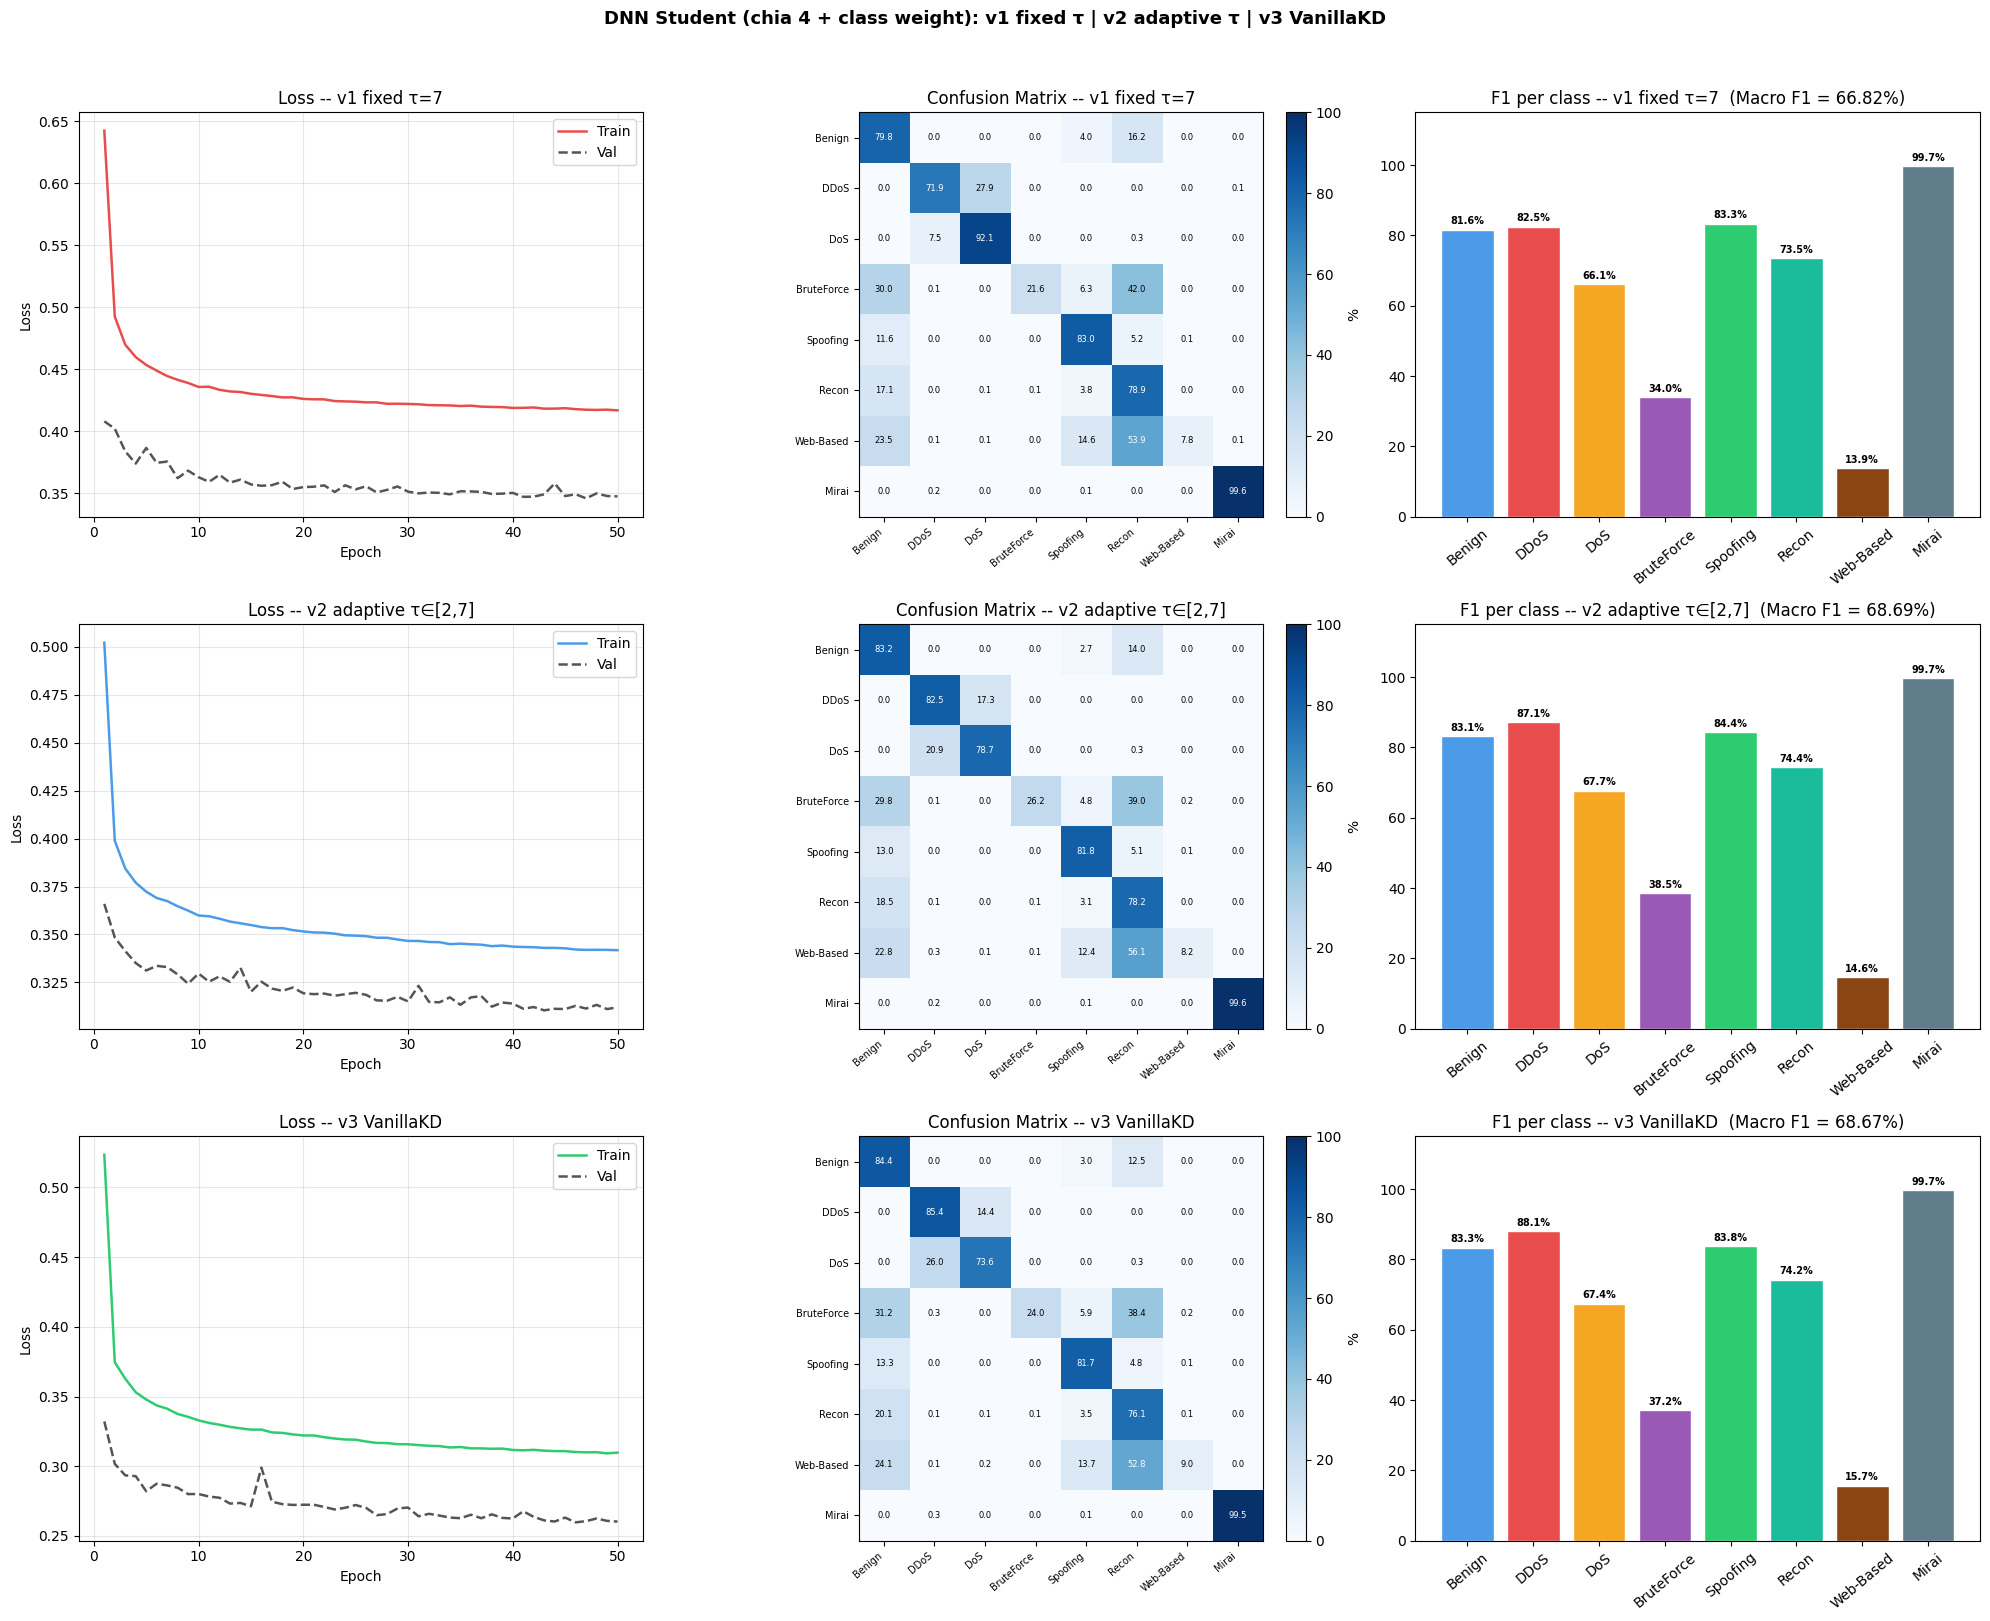

Plot -> /kaggle/working/compare_dnn_v1_v2_v3.png


In [10]:
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
fig.suptitle('DNN Student (chia 4 + class weight): v1 fixed τ | v2 adaptive τ | v3 VanillaKD',
             fontsize=13, fontweight='bold', y=1.01)

for row, (tl, vl, preds, labels, label, color) in enumerate([
    (tl_v1, vl_v1, preds_v1, labels_v1, 'v1 fixed τ=7',        '#E84C4C'),
    (tl_v2, vl_v2, preds_v2, labels_v2, 'v2 adaptive τ∈[2,7]', '#4C9BE8'),
    (tl_v3, vl_v3, preds_v3, labels_v3, 'v3 VanillaKD',        '#2ECC71'),
]):
    ep = range(1, len(tl) + 1)
    axes[row,0].plot(ep, tl, label='Train', color=color, lw=1.8)
    axes[row,0].plot(ep, vl, label='Val', color='#555555', lw=1.8, ls='--')
    axes[row,0].set_title(f'Loss -- {label}'); axes[row,0].set_xlabel('Epoch'); axes[row,0].set_ylabel('Loss')
    axes[row,0].legend(); axes[row,0].grid(alpha=0.3)

    cm = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    im = axes[row,1].imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
    plt.colorbar(im, ax=axes[row,1], fraction=0.046, pad=0.04, label='%')
    axes[row,1].set_xticks(range(NUM_CLASSES)); axes[row,1].set_yticks(range(NUM_CLASSES))
    axes[row,1].set_xticklabels(CLASS_NAMES, rotation=40, ha='right', fontsize=7)
    axes[row,1].set_yticklabels(CLASS_NAMES, fontsize=7)
    axes[row,1].set_title(f'Confusion Matrix -- {label}')
    thr = cm_pct.max()/2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            axes[row,1].text(j, i, f'{cm_pct[i,j]:.1f}', ha='center', va='center',
                             fontsize=6, color='white' if cm_pct[i,j] > thr else 'black')

    f1s = f1_score(labels, preds, average=None, zero_division=0)
    bars = axes[row,2].bar(CLASS_NAMES, f1s*100, color=COLORS, edgecolor='white')
    axes[row,2].set_ylim(0, 115)
    axes[row,2].set_title(f'F1 per class -- {label}  (Macro F1 = {np.mean(f1s)*100:.2f}%)')
    axes[row,2].tick_params(axis='x', rotation=40)
    for bar, val in zip(bars, f1s):
        axes[row,2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
                         f'{val*100:.1f}%', ha='center', fontsize=7, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.99])
plot_path = os.path.join(OUTPUT_DIR, 'compare_dnn_v1_v2_v3.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight'); plt.show()
print(f'Plot -> {plot_path}')


## Cell 11 — Export config & tổng kết

In [11]:
class StudentInferenceOnly(nn.Module):
    def __init__(self,body,head): super().__init__(); self.body=body; self.head=head
    def forward(self,x): return self.head(self.body(x))
def export_cfg(student,version,acc,auc,di):
    npar=count_params(student)
    cfg={'model':f'KD-Student-{version}-MiniDNN','teacher':'DNN-256-256-256',
         'student_filters':FILTERS_STUDENT,'distillation':di,'class_weight_max':CLASS_WEIGHT_MAX,
         'optimizer':'Adam','weight_decay':0,
         'performance':{'accuracy':round(float(acc),6),'macro_auc':round(float(auc),6),
                        'params':npar,'size_mb_fp32':round(npar*4/1024**2,4),'compression':round(1-npar/t_params,4)}}
    json.dump(cfg,open(os.path.join(OUTPUT_DIR,f'config_{version}.json'),'w'),indent=2)
    infer=StudentInferenceOnly(student.body.cpu().eval(),student.head.cpu().eval())
    try:
        op=os.path.join(OUTPUT_DIR,f'student_dnn_{version}.onnx')
        torch.onnx.export(infer,torch.randn(1,NUM_FEATURES),op,input_names=['features'],output_names=['logits'],
                          dynamic_axes={'features':{0:'batch'},'logits':{0:'batch'}},opset_version=13)
        print(f'ONNX -> {op} ({os.path.getsize(op)/1024:.1f} KB)')
    except Exception as e: print(f'  ONNX ERR: {e}')
    student.to(DEVICE)
export_cfg(student_v1,'v1',acc_v1,auc_v1,{'method':'RAID-KL','alpha':ALPHA,'lambda':LAMBDA,'tau':TAU_FIXED,'tau_mode':'fixed'})
export_cfg(student_v2,'v2',acc_v2,auc_v2,{'method':'RAID-KL','alpha':ALPHA,'lambda':LAMBDA,'tau_min':TAU_MIN,'tau_max':TAU_MAX,'tau_mode':'adaptive'})
export_cfg(student_v3,'v3',acc_v3,auc_v3,{'method':'VanillaKD','alpha':VKD_ALPHA,'T':VKD_T})
print('\n'+'='*62); print('  DNN -- TONG KET 3 STUDENT (chia 4 + class weight)'); print('='*62)
print(f'  {"":22s}  {"v1 fixed":>12}  {"v2 adaptive":>12}  {"v3 Vanilla":>12}')
print(f'  {"Accuracy":22s}  {acc_v1*100:>11.4f}%  {acc_v2*100:>11.4f}%  {acc_v3*100:>11.4f}%')
print(f'  {"Macro AUC":22s}  {auc_v1:>12.6f}  {auc_v2:>12.6f}  {auc_v3:>12.6f}')
print('='*62)
print('\nOutput .pth:')
for fn in sorted(os.listdir(OUTPUT_DIR)):
    if fn.endswith('.pth'): print(f'  {fn:<45} {os.path.getsize(os.path.join(OUTPUT_DIR,fn))/1024:>8.1f} KB')


  ONNX ERR: No module named 'onnxscript'
  ONNX ERR: No module named 'onnxscript'
  ONNX ERR: No module named 'onnxscript'

  DNN -- TONG KET 3 STUDENT (chia 4 + class weight)
                              v1 fixed   v2 adaptive    v3 Vanilla
  Accuracy                    80.4430%      83.5052%      84.0453%
  Macro AUC                   0.975887      0.977330      0.976979

Output .pth:
  student_dnn_adapt_t_classw3_37ft.pth             120.0 KB
  student_dnn_fix_t_classw3_37ft.pth                55.7 KB
  student_dnn_vanilla_kd_classw3_37ft.pth           55.8 KB
